# 03 · Resultados

Lee `results/metrics_2d.csv` (reconstrucción 2D) y `results/metrics_3d.csv` (3DGS), y genera
tablas y gráficos. **No inventa números:** si un archivo no existe o le faltan condiciones, lo
indica y omite la parte correspondiente.

- **2D:** promedio sobre las 24 vistas de la imagen reconstruida, a resolución completa, contra la
  imagen original. Incluye la pérdida por remuestreo a la rejilla.
- **3D:** promedio sobre las 3 vistas de prueba del render 3DGS contra la imagen original.

**Filtros.** `results/metrics_2d.csv` tiene filas de dos rejillas (256×512 y 512×1024) y
`results/metrics_3d.csv` corridas con varias semillas (449, 450 y 451). Para no promediar
condiciones distintas, cada tabla y gráfico usa **una sola rejilla y una sola semilla**:
la 2D se muestra por rejilla y la 3D usa `REJILLA` y `SEMILLA` (celda siguiente). El
baseline de cada número de iteraciones es la corrida `original` con esa semilla. Si una
combinación se ejecutó más de una vez, se usa la **última** fila registrada.

In [1]:
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
import pandas as pd
import matplotlib.pyplot as plt

RES = RAIZ / "results"
# Las figuras de esta versión van a una carpeta nueva: no se sobrescriben las de results/figuras/.
FIG = RES / "figuras" / "orden-informe"
FIG.mkdir(parents=True, exist_ok=True)

# Codificación fija por serie: el color identifica (patrón, método) y nunca cambia entre
# gráficos; el estilo de línea distingue el método y el marcador el patrón, para que la
# identidad no dependa solo del color.
SERIES = {
    ("hadamard", "directa"): dict(color="#2a78d6", ls="--", marker="o"),
    ("hadamard", "tv"):      dict(color="#eb6834", ls="-",  marker="o"),
    ("random", "directa"):   dict(color="#1baf7a", ls="--", marker="s"),
    ("random", "tv"):        dict(color="#eda100", ls="-",  marker="s"),
    ("dct", "directa"):      dict(color="#e87ba4", ls="--", marker="^"),
    ("dct", "tv"):           dict(color="#008300", ls="-",  marker="^"),
}
# Filtros (ver la descripción): rejilla de las condiciones 3D y semilla de todas las tablas.
REJILLA = "256x512"
SEMILLA = 449
GRIS = "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
                     "lines.linewidth": 2, "lines.markersize": 7})


def leer(nombre, claves):
    ruta = RES / nombre
    if not ruta.exists():
        print(f"No existe {ruta.relative_to(RAIZ)}: todavía no hay corridas de este tipo.")
        return None
    df = pd.read_csv(ruta)
    if df.empty:
        print(f"{ruta.relative_to(RAIZ)} está vacío.")
        return None
    return df.drop_duplicates(subset=claves, keep="last").reset_index(drop=True)


df2 = leer("metrics_2d.csv", ["escena", "patron", "metodo", "razon", "rejilla", "semilla"])
df3 = leer("metrics_3d.csv", ["escena", "patron", "metodo", "razon", "rejilla",
                              "iteraciones", "semilla", "factor"])


def filtrar(df, rejillas, semilla=SEMILLA):
    """Filas de las rejillas indicadas y de una semilla. El baseline original no pasa por la
    rejilla (rejilla "-"), por eso se conserva siempre."""
    if df is None:
        return None
    sel = df["rejilla"].isin(list(rejillas) + ["-"]) & (df["semilla"] == semilla)
    return df[sel].reset_index(drop=True)


if df2 is not None:
    REJILLAS_2D = sorted(df2["rejilla"].unique(), key=lambda r: int(r.split("x")[0]))
    n = len(df2)
    df2 = filtrar(df2, REJILLAS_2D)
    print(f"2D: {len(df2)} de {n} filas (semilla {SEMILLA}; rejillas {', '.join(REJILLAS_2D)})")
if df3 is not None:
    n = len(df3)
    df3 = filtrar(df3, [REJILLA])
    print(f"3D: {len(df3)} de {n} filas (rejilla {REJILLA} y baseline original; semilla {SEMILLA})")

2D: 50 de 50 filas (semilla 449; rejillas 256x512, 512x1024)
3D: 38 de 48 filas (rejilla 256x512 y baseline original; semilla 449)


In [2]:
def tabla_por_razon(df, metrica):
    """Filas = (patrón, método); columnas = razón de muestreo (%)."""
    spc = df[~df["patron"].isin(["original", "control"])]
    if spc.duplicated(["patron", "metodo", "razon"]).any():
        raise ValueError("Hay más de una fila por (patrón, método, razón): filtre por rejilla "
                         "y semilla antes de tabular.")
    t = spc.pivot_table(index=["patron", "metodo"], columns="razon", values=metrica)
    t.columns = [f"{int(round(c * 100))} %" for c in t.columns]
    return t.round(2 if metrica.startswith("PSNR") else 3)


def grafico(df, titulo, archivo, referencias, sufijo=""):
    """PSNR, SSIM y LPIPS frente a la razón; líneas horizontales para las referencias.
    sufijo="_ent" usa las métricas en vistas de entrenamiento."""
    spc = df[~df["patron"].isin(["original", "control"])]
    fig, ejes = plt.subplots(1, 3, figsize=(17, 4.6))
    for eje, metrica in zip(ejes, ["PSNR", "SSIM", "LPIPS"]):
        for (patron, metodo), g in spc.groupby(["patron", "metodo"]):
            g = g.sort_values("razon")
            estilo = SERIES.get((patron, metodo), {})
            eje.plot(g["razon"] * 100, g[metrica + sufijo], label=f"{patron} · {metodo}", **estilo)
        for nombre, fila, ls in referencias:
            eje.axhline(fila[metrica + sufijo], color=GRIS, ls=ls, lw=1.2)
            # Etiqueta dentro del eje, alineada a la derecha, sobre la línea.
            eje.annotate(nombre, (0.99, fila[metrica + sufijo]), xycoords=("axes fraction", "data"),
                         xytext=(0, 3), textcoords="offset points", ha="right",
                         color=GRIS, fontsize=9)
        eje.set_xlabel("mediciones (% de píxeles de la rejilla)")
        eje.set_xticks([5, 10, 25, 50])
        eje.set_title(f"{metrica} ({'menor' if metrica == 'LPIPS' else 'mayor'} es mejor)")
    ejes[0].set_ylabel("valor promedio")
    ejes[0].legend(frameon=False, fontsize=9)
    fig.suptitle(titulo)
    plt.tight_layout()
    fig.savefig(FIG / archivo, dpi=120)
    plt.show()

## 1. Reconstrucción 2D

Pérdida de calidad de la imagen reconstruida frente a la original. La fila `control` es el
remuestreo a la rejilla sin SPC: ninguna condición SPC puede superarla, porque se mide sobre la
misma rejilla. Se muestra una tabla y un gráfico por rejilla.


########## Rejilla 256x512 ##########

PSNR 2D (promedio de 24 vistas)


5 %   10 %   25 %   50 %
patron   metodo                             
dct      directa  21.61  22.88  24.91  26.43
         tv       21.80  23.18  25.17  26.49
hadamard directa  20.63  21.89  23.92  25.92
         tv       21.52  22.90  24.87  26.33
random   directa  12.65  12.93  13.87  15.82
         tv       20.35  21.89  24.39  26.12


SSIM 2D (promedio de 24 vistas)


5 %   10 %   25 %   50 %
patron   metodo                             
dct      directa  0.583  0.640  0.748  0.823
         tv       0.602  0.665  0.763  0.820
hadamard directa  0.529  0.582  0.702  0.799
         tv       0.597  0.660  0.754  0.814
random   directa  0.245  0.197  0.170  0.202
         tv       0.554  0.602  0.701  0.785


LPIPS 2D (promedio de 24 vistas)


5 %   10 %   25 %   50 %
patron   metodo                             
dct      directa  0.545  0.468  0.351  0.248
         tv       0.547  0.467  0.328  0.251
hadamard directa  0.588  0.521  0.391  0.281
         tv       0.552  0.470  0.342  0.260
random   directa  0.650  0.652  0.648  0.629
         tv       0.602  0.553  0.440  0.315

,rejilla,PSNR,SSIM,LPIPS,condicion
0,256x512,27.2219,0.8579,0.1947,control


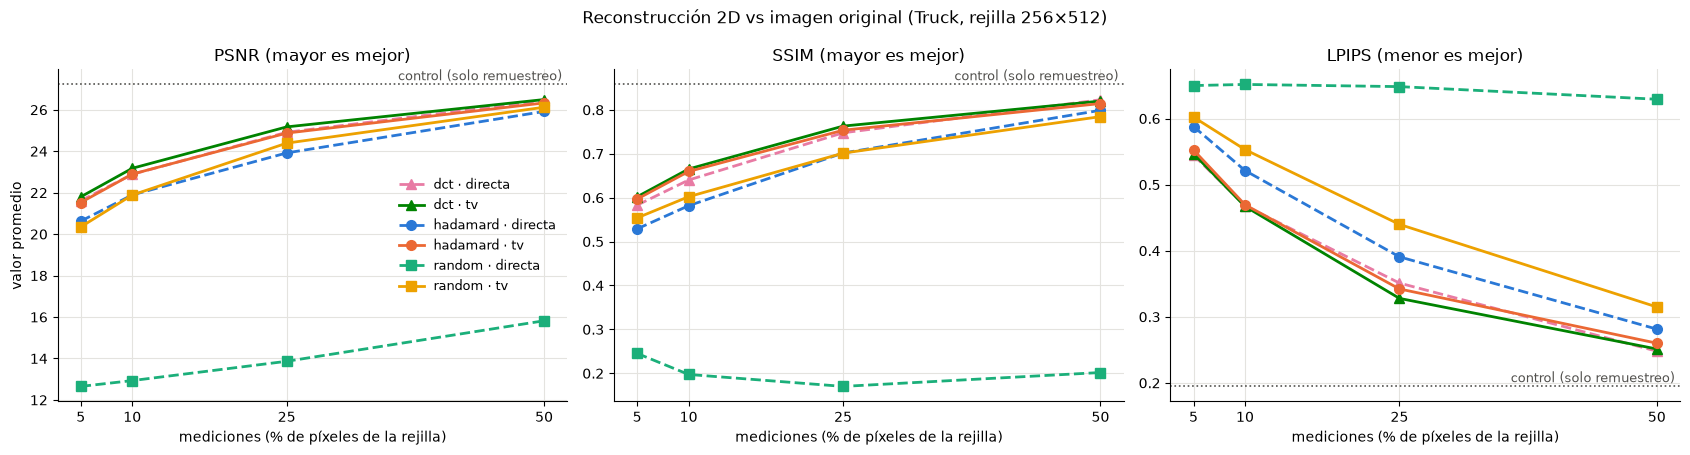


########## Rejilla 512x1024 ##########

PSNR 2D (promedio de 24 vistas)


5 %   10 %   25 %   50 %
patron   metodo                             
dct      directa  24.62  26.79  30.92  35.11
         tv       24.99  27.31  31.33  34.99
hadamard directa  23.17  25.04  28.48  33.12
         tv       24.54  26.72  30.54  34.39
random   directa  12.68  13.00  14.03  16.24
         tv       23.21  25.49  29.74  33.71


SSIM 2D (promedio de 24 vistas)


5 %   10 %   25 %   50 %
patron   metodo                             
dct      directa  0.719  0.812  0.921  0.969
         tv       0.750  0.837  0.927  0.964
hadamard directa  0.662  0.750  0.880  0.953
         tv       0.738  0.824  0.916  0.959
random   directa  0.244  0.203  0.194  0.248
         tv       0.648  0.727  0.851  0.929


LPIPS 2D (promedio de 24 vistas)


5 %   10 %   25 %   50 %
patron   metodo                             
dct      directa  0.397  0.294  0.139  0.054
         tv       0.396  0.262  0.121  0.066
hadamard directa  0.456  0.363  0.199  0.095
         tv       0.410  0.278  0.140  0.074
random   directa  0.722  0.721  0.703  0.655
         tv       0.535  0.456  0.280  0.136

,rejilla,PSNR,SSIM,LPIPS,condicion
25,512x1024,38.0003,0.9848,0.0274,control


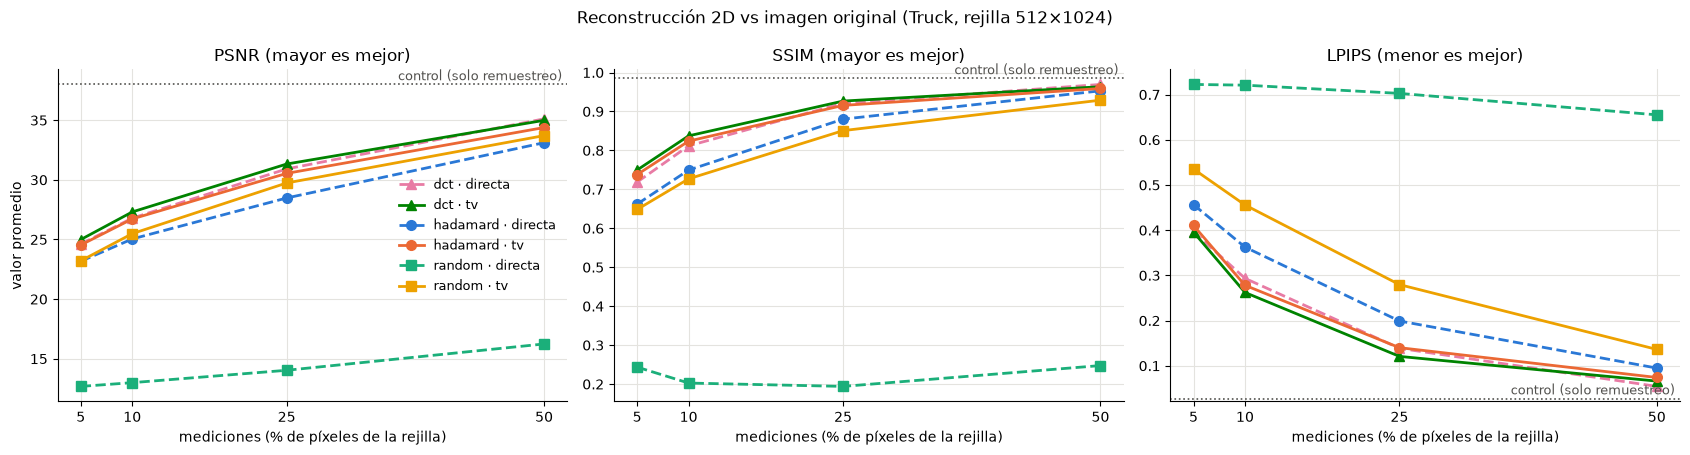

In [3]:
if df2 is not None:
    for rejilla in REJILLAS_2D:
        d2 = df2[df2["rejilla"] == rejilla]
        control2 = d2[d2["patron"] == "control"]
        print(f"\n########## Rejilla {rejilla} ##########")
        for metrica in ["PSNR", "SSIM", "LPIPS"]:
            print(f"\n{metrica} 2D (promedio de {int(d2['vistas'].iloc[0])} vistas)")
            display(tabla_por_razon(d2, metrica))
        if not control2.empty:
            display(control2[["rejilla", "PSNR", "SSIM", "LPIPS"]].assign(condicion="control"))
            grafico(d2, f"Reconstrucción 2D vs imagen original (Truck, rejilla {rejilla.replace('x', '×')})",
                    f"metricas_2d_{rejilla}.png", [("control (solo remuestreo)", control2.iloc[-1], ":")])
        else:
            print(f"Falta la condición control de la rejilla {rejilla} en metrics_2d.csv.")

## 2. 3DGS: renders de prueba frente a las imágenes originales

Una tabla y un gráfico por número de iteraciones. `original` es el baseline entrenado con las
imágenes sin degradar y `control` el entrenado con las imágenes remuestreadas.


===== 3000 iteraciones =====


,patron,PSNR,SSIM,LPIPS,gaussianas,tiempo_s,mem_max_GiB
0,control,18.4908,0.6614,0.4139,501384,72.4,1.320
1,original,17.9689,0.6763,0.3654,779908,78.7,1.953


PSNR 3D


5 %   10 %   25 %   50 %
patron   metodo                             
hadamard directa  17.63  17.60  18.25  18.20
         tv       17.88  18.15  18.28  18.36
random   directa  12.16  12.37  12.76  13.88
         tv       17.53  17.62  18.50  18.57

SSIM 3D


5 %   10 %   25 %   50 %
patron   metodo                             
hadamard directa  0.510  0.541  0.601  0.642
         tv       0.553  0.586  0.627  0.650
random   directa  0.317  0.275  0.219  0.235
         tv       0.524  0.549  0.602  0.639

LPIPS 3D


5 %   10 %   25 %   50 %
patron   metodo                             
hadamard directa  0.563  0.537  0.480  0.438
         tv       0.566  0.523  0.470  0.438
random   directa  0.675  0.663  0.652  0.629
         tv       0.616  0.578  0.510  0.459

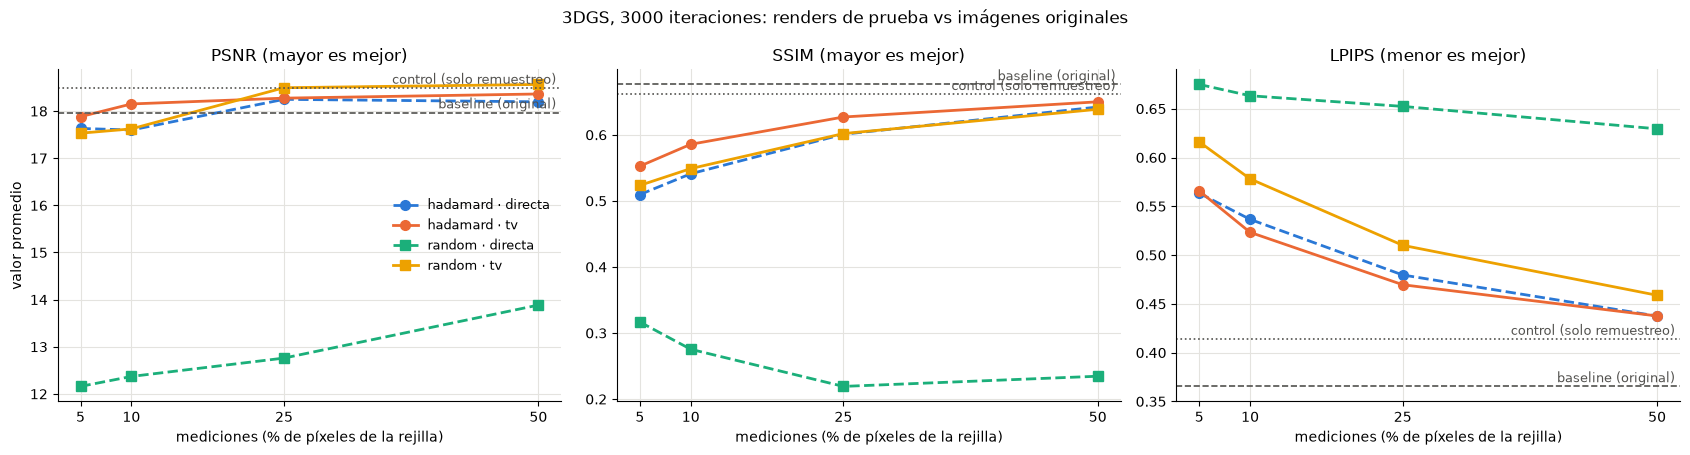


===== 7000 iteraciones =====


,patron,PSNR,SSIM,LPIPS,gaussianas,tiempo_s,mem_max_GiB
0,control,18.2504,0.6508,0.4129,677023,197.7,1.609
1,original,17.7157,0.6625,0.3547,1363825,275.7,3.346


PSNR 3D


5 %   10 %   25 %   50 %
patron   metodo                             
hadamard directa  17.18  17.18  17.79  18.08
         tv       17.81  17.90  17.90  18.07
random   directa  12.13  12.21  12.49  13.41
         tv       17.27  17.43  18.05  18.16

SSIM 3D


5 %   10 %   25 %   50 %
patron   metodo                             
hadamard directa  0.486  0.512  0.580  0.628
         tv       0.538  0.574  0.614  0.639
random   directa  0.264  0.213  0.172  0.183
         tv       0.507  0.532  0.586  0.626

LPIPS 3D


5 %   10 %   25 %   50 %
patron   metodo                             
hadamard directa  0.566  0.539  0.482  0.439
         tv       0.565  0.523  0.470  0.434
random   directa  0.667  0.667  0.662  0.647
         tv       0.616  0.581  0.517  0.460

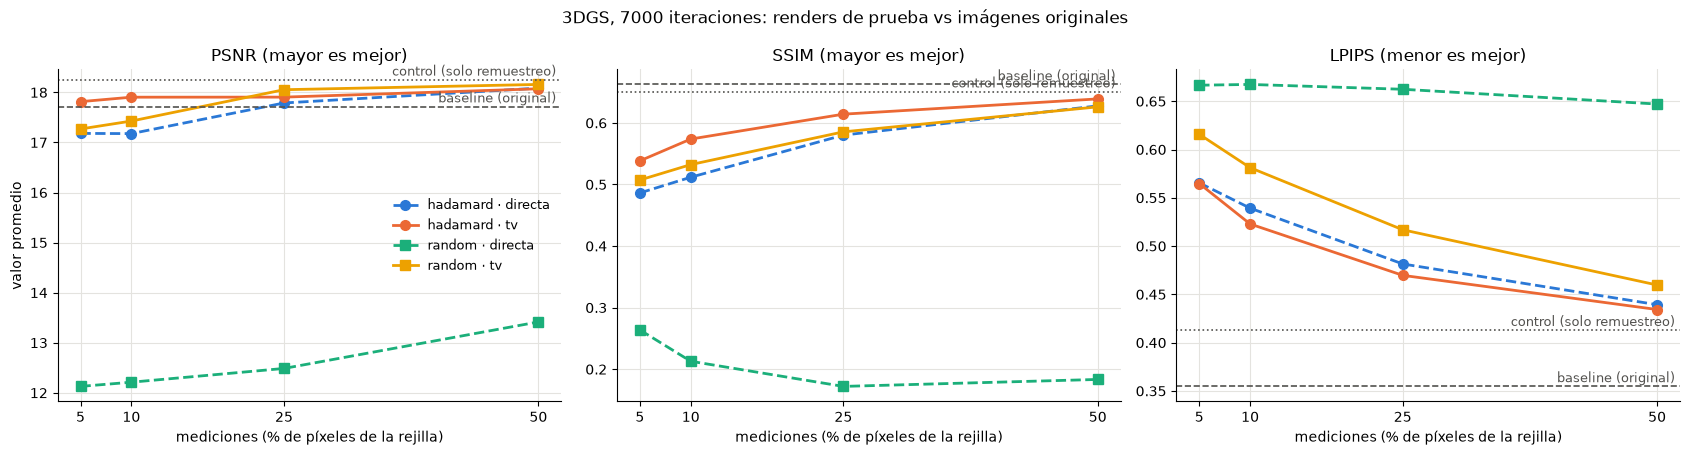


===== 30000 iteraciones =====


,patron,PSNR,SSIM,LPIPS,gaussianas,tiempo_s,mem_max_GiB
0,control,18.0612,0.6314,0.4145,916899,1140.4,2.219
1,original,17.2029,0.6186,0.3674,2486966,3495.4,5.652


Todavía no hay condiciones SPC con estas iteraciones.


In [4]:
if df3 is not None:
    for it, d in df3.groupby("iteraciones"):
        print(f"\n===== {it} iteraciones =====")
        ref = d[d["patron"].isin(["original", "control"])][["patron", "PSNR", "SSIM", "LPIPS",
                                                           "gaussianas", "tiempo_s", "mem_max_GiB"]]
        display(ref.reset_index(drop=True))
        if (d["patron"].isin(["original", "control"])).all():
            print("Todavía no hay condiciones SPC con estas iteraciones.")
            continue
        for metrica in ["PSNR", "SSIM", "LPIPS"]:
            print(f"{metrica} 3D")
            display(tabla_por_razon(d, metrica))
        refs = [(n, d[d["patron"] == p].iloc[-1], ls)
                for n, p, ls in [("baseline (original)", "original", "--"),
                                 ("control (solo remuestreo)", "control", ":")]
                if (d["patron"] == p).any()]
        grafico(d, f"3DGS, {it} iteraciones: renders de prueba vs imágenes originales",
                f"metricas_3d_it{it}.png", refs)

## 3. 3DGS en las vistas de entrenamiento (complemento)

Con solo 21 vistas, el error en las vistas de **prueba** está dominado por artefactos de
generalización (zonas poco observadas, "floaters"), que afectan por igual a todas las condiciones
y ocultan parte del efecto del SPC. Como complemento, se renderizan las **21 vistas de
entrenamiento** y se comparan con sus imágenes **originales** (nunca con las degradadas con que se
entrenó). Esto mide cuánta de la degradación del SPC hereda el modelo 3D allí donde sí hay
observaciones. Columnas `PSNR_ent`, `SSIM_ent` y `LPIPS_ent`.


===== 3000 iteraciones (vistas de entrenamiento vs originales) =====


,patron,PSNR_ent,SSIM_ent,LPIPS_ent
0,control,25.8967,0.8241,0.2935
1,original,28.8118,0.9144,0.2084


5 %   10 %   25 %   50 %
patron   metodo                             
hadamard directa  20.68  21.88  23.69  25.20
         tv       21.46  22.71  24.39  25.40
random   directa  12.80  13.12  14.18  16.40
         tv       20.32  21.76  23.95  25.18

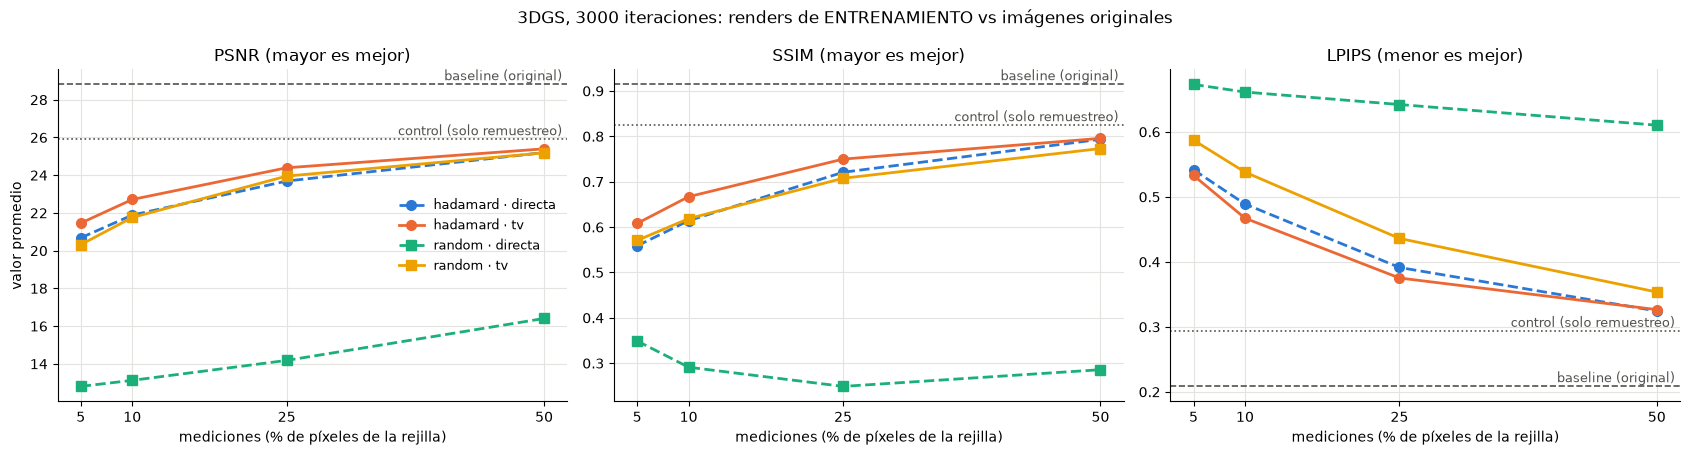


===== 7000 iteraciones (vistas de entrenamiento vs originales) =====


,patron,PSNR_ent,SSIM_ent,LPIPS_ent
0,control,26.6264,0.8396,0.2683
1,original,32.5131,0.9516,0.1521


5 %   10 %   25 %   50 %
patron   metodo                             
hadamard directa  20.63  21.89  23.86  25.66
         tv       21.48  22.80  24.67  25.90
random   directa  12.74  13.04  14.03  16.08
         tv       20.32  21.83  24.19  25.73

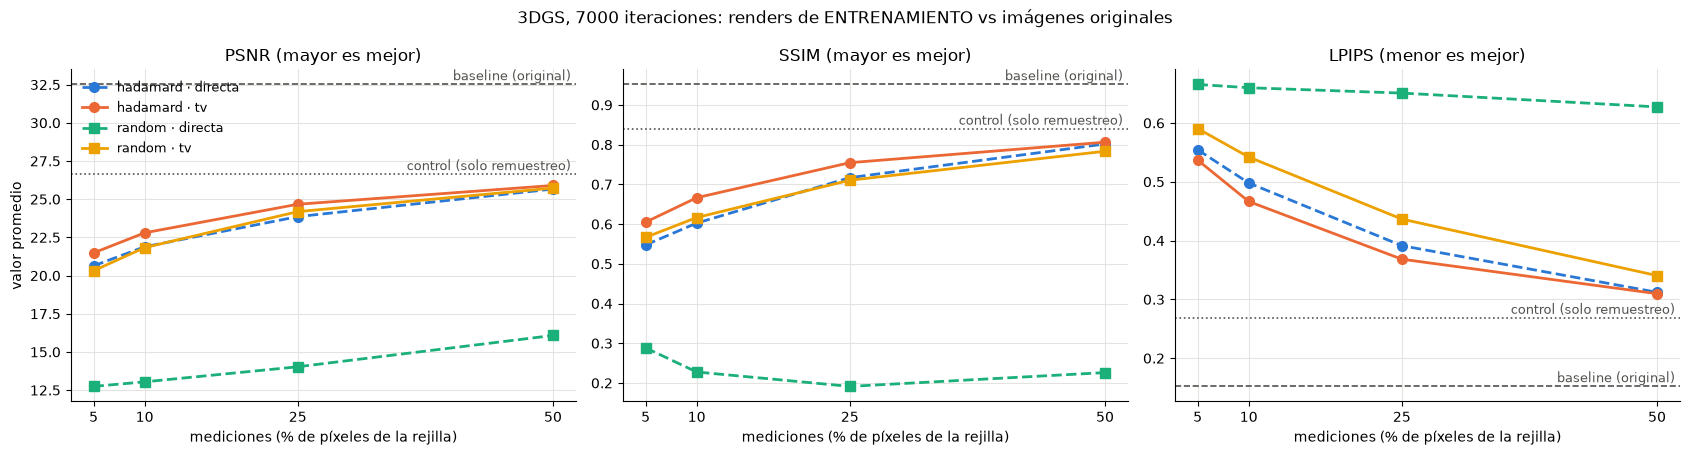


===== 30000 iteraciones (vistas de entrenamiento vs originales) =====


,patron,PSNR_ent,SSIM_ent,LPIPS_ent
0,control,27.0448,0.8508,0.2379
1,original,40.2277,0.9799,0.0798


In [5]:
if df3 is not None and "PSNR_ent" in df3.columns:
    d_ent = df3.dropna(subset=["PSNR_ent"])
    if d_ent.empty:
        print("Ninguna corrida tiene todavía métricas en vistas de entrenamiento "
              "(reevaluar con: python scripts/eval_3d.py --todas truck).")
    for it, d in d_ent.groupby("iteraciones"):
        print(f"\n===== {it} iteraciones (vistas de entrenamiento vs originales) =====")
        display(d[d["patron"].isin(["original", "control"])][["patron", "PSNR_ent", "SSIM_ent", "LPIPS_ent"]]
                .reset_index(drop=True))
        if (d["patron"].isin(["original", "control"])).all():
            continue
        display(tabla_por_razon(d, "PSNR_ent"))
        refs = [(n, d[d["patron"] == p].iloc[-1], ls)
                for n, p, ls in [("baseline (original)", "original", "--"),
                                 ("control (solo remuestreo)", "control", ":")]
                if (d["patron"] == p).any()]
        grafico(d, f"3DGS, {it} iteraciones: renders de ENTRENAMIENTO vs imágenes originales",
                f"metricas_3d_ent_it{it}.png", refs, sufijo="_ent")
else:
    print("metrics_3d.csv no tiene métricas en vistas de entrenamiento.")

## 4. Pérdida respecto del baseline y relación 2D → 3D

ΔPSNR = PSNR(condición) − PSNR(baseline original), con las mismas iteraciones. Un valor más
negativo indica mayor pérdida. El último gráfico compara, para cada condición, la calidad 2D
de las imágenes con que se entrenó 3DGS con la calidad 3D de los renders de prueba.

El eje 2D es el promedio de las **21 vistas de entrenamiento** (las únicas que ve 3DGS), leído
de `results/metrics_2d_por_vista.csv` (generado por `scripts/metricas_2d_por_vista.py`). Antes
se usaba el promedio de las 24 vistas de `results/metrics_2d.csv`, que incluye las 3 de prueba;
la diferencia es de −0,10 a +0,07 dB según la condición (ver
`results/auditoria/eje_2d_3d_antes_despues.csv`).


===== 3000 iteraciones =====


,patron,metodo,razon,vistas_2D,PSNR_2D,PSNR_3D,dPSNR_3D
0,control,-,1.00,21,27.12,18.49,0.52
1,hadamard,directa,0.05,21,20.54,17.63,-0.34
2,hadamard,directa,0.10,21,21.80,17.60,-0.37
3,hadamard,directa,0.25,21,23.83,18.25,0.28
4,hadamard,directa,0.50,21,25.83,18.20,0.23
5,hadamard,tv,0.05,21,21.43,17.88,-0.09
6,hadamard,tv,0.10,21,22.80,18.15,0.18
7,hadamard,tv,0.25,21,24.78,18.28,0.31
8,hadamard,tv,0.50,21,26.24,18.36,0.39
9,random,directa,0.05,21,12.72,12.16,-5.81


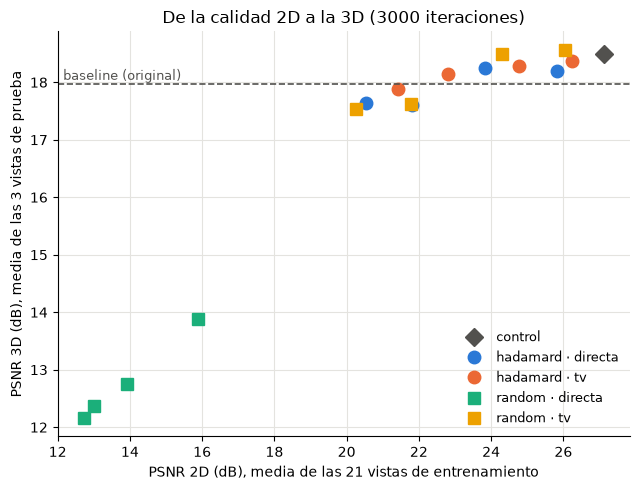


===== 7000 iteraciones =====


,patron,metodo,razon,vistas_2D,PSNR_2D,PSNR_3D,dPSNR_3D
0,control,-,1.00,21,27.12,18.25,0.53
1,hadamard,directa,0.05,21,20.54,17.18,-0.54
2,hadamard,directa,0.10,21,21.80,17.18,-0.54
3,hadamard,directa,0.25,21,23.83,17.79,0.07
4,hadamard,directa,0.50,21,25.83,18.08,0.37
5,hadamard,tv,0.05,21,21.43,17.81,0.10
6,hadamard,tv,0.10,21,22.80,17.90,0.19
7,hadamard,tv,0.25,21,24.78,17.90,0.19
8,hadamard,tv,0.50,21,26.24,18.07,0.36
9,random,directa,0.05,21,12.72,12.13,-5.59


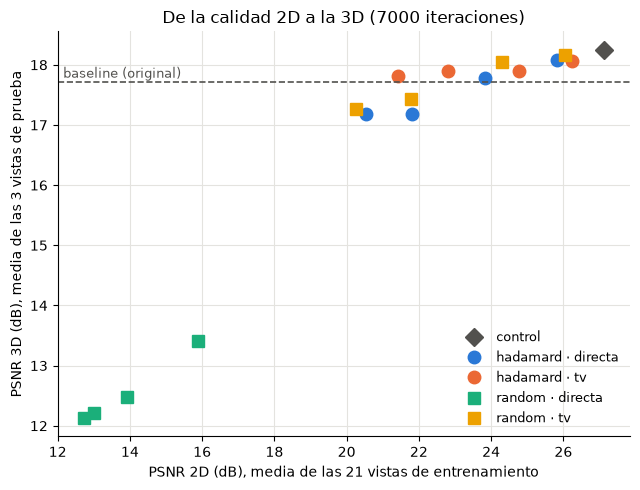


===== 30000 iteraciones =====


,patron,metodo,razon,vistas_2D,PSNR_2D,PSNR_3D,dPSNR_3D
0,control,-,1.0,21,27.12,18.06,0.86


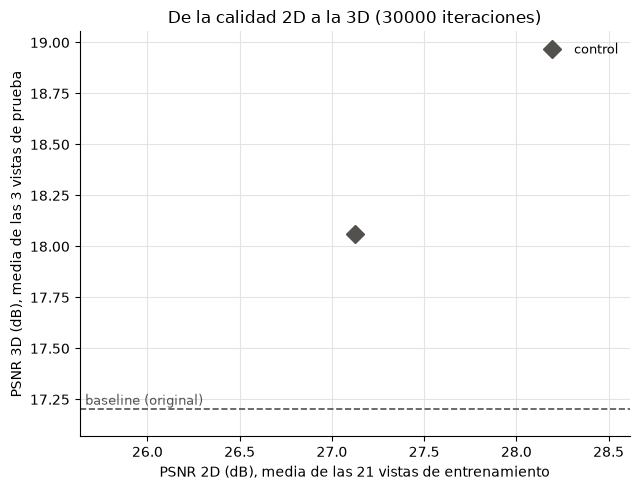

In [6]:
RUTA_2D_VISTAS = RES / "metrics_2d_por_vista.csv"
if df3 is not None and RUTA_2D_VISTAS.exists():
    claves = ["patron", "metodo", "razon"]
    vistas2d = pd.read_csv(RUTA_2D_VISTAS)
    psnr2d_ent = (vistas2d[vistas2d["conjunto"] == "entrenamiento"]
                  .groupby("condicion")["PSNR"].agg(PSNR_2D="mean", vistas_2D="size")
                  .reset_index())
    for it, d in df3.groupby("iteraciones"):
        base = d[d["patron"] == "original"]
        if base.empty:
            print(f"{it} iteraciones: falta el baseline original.")
            continue
        assert len(base) == 1, "debe haber un único baseline por iteraciones y semilla"
        d = d.assign(dPSNR_3D=d["PSNR"] - base["PSNR"].iloc[-1])
        # Eje 2D: promedio de las 21 vistas de entrenamiento de cada condición.
        unido = d.merge(psnr2d_ent, on="condicion", how="inner")
        print(f"\n===== {it} iteraciones =====")
        display(unido[claves + ["vistas_2D", "PSNR_2D", "PSNR", "dPSNR_3D"]]
                .rename(columns={"PSNR": "PSNR_3D"}).round(2))
        fig, eje = plt.subplots(figsize=(6.5, 5))
        for (patron, metodo), g in unido.groupby(["patron", "metodo"]):
            if (patron, metodo) in SERIES:
                e = SERIES[(patron, metodo)]
                eje.plot(g["PSNR_2D"], g["PSNR"], ls="none", marker=e["marker"], color=e["color"],
                         markersize=9, label=f"{patron} · {metodo}")
            else:  # control
                eje.plot(g["PSNR_2D"], g["PSNR"], ls="none", marker="D", color=GRIS,
                         markersize=9, label=patron)
        eje.axhline(base["PSNR"].iloc[-1], color=GRIS, ls="--", lw=1.2)
        eje.annotate("baseline (original)", (eje.get_xlim()[0], base["PSNR"].iloc[-1]),
                     xytext=(4, 3), textcoords="offset points", color=GRIS, fontsize=9)
        eje.set_xlabel("PSNR 2D (dB), media de las 21 vistas de entrenamiento")
        eje.set_ylabel("PSNR 3D (dB), media de las 3 vistas de prueba")
        eje.set_title(f"De la calidad 2D a la 3D ({it} iteraciones)")
        eje.legend(frameon=False, fontsize=9)
        plt.tight_layout()
        fig.savefig(FIG / f"relacion_2d_3d_it{it}.png", dpi=120)
        plt.show()
else:
    print("Se necesitan results/metrics_3d.csv y results/metrics_2d_por_vista.csv "
          "(python scripts/metricas_2d_por_vista.py) para esta sección.")